In [1]:
'''Build a secure and user-friendly functionality within Streamlit applications to allow users to
 upload, validate, and analyze their datasets for customized predictions and insights generation.'''

'Build a secure and user-friendly functionality within Streamlit applications to allow users to\n upload, validate, and analyze their datasets for customized predictions and insights generation.'

In [2]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

In [3]:
# loading the pharmacy dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

Out[1]: 
         date  year  month  ...  stock_level expiry_days_remaining covid_flag
0  2025-10-12  2025     10  ...         4774                   466          0
1  2020-09-15  2020      9  ...         4584                   181          1
2  2020-02-26  2020      2  ...         3934                   556          1
3  2025-11-09  2025     11  ...         4544                   330          0
4  2022-04-04  2022      4  ...         4284                   590          0

[5 rows x 14 columns]


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# inspecting dataset information and dimensions
print('dataset shape:', df.shape)
df.info()

dataset shape: (177990, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177990 entries, 0 to 177989
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date                   177990 non-null  object 
 1   year                   177990 non-null  int64  
 2   month                  177990 non-null  int64  
 3   day                    177990 non-null  int64  
 4   region                 177990 non-null  object 
 5   country                177990 non-null  object 
 6   category               177990 non-null  object 
 7   medicine               177990 non-null  object 
 8   age_group              177990 non-null  object 
 9   units_sold             177990 non-null  int64  
 10  unit_price             177990 non-null  float64
 11  stock_level            177990 non-null  int64  
 12  expiry_days_remaining  177990 non-null  int64  
 13  covid_flag             177990 non-null  int64  
dtypes: float

In [5]:
# checking summary statistics of numerical columns
df.describe()

Out[1]: 
                year          month  ...  expiry_days_remaining     covid_flag
count  177990.000000  177990.000000  ...          177990.000000  177990.000000
mean     2022.499702       6.521754  ...             374.038109       0.333519
std         1.708113       3.448703  ...             199.759193       0.471471
min      2020.000000       1.000000  ...              30.000000       0.000000
25%      2021.000000       4.000000  ...             200.000000       0.000000
50%      2023.000000       7.000000  ...             374.000000       0.000000
75%      2024.000000      10.000000  ...             547.000000       1.000000
max      2025.000000      12.000000  ...             720.000000       1.000000

[8 rows x 8 columns]


,year,month,day,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
count,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000
mean,2022.499702,6.521754,15.730457,447.913849,52.554729,4552.991780,374.038109,0.333519
std,1.708113,3.448703,8.801170,338.924528,27.421909,346.608511,199.759193,0.471471
min,2020.000000,1.000000,1.000000,31.000000,5.000000,0.000000,30.000000,0.000000
25%,2021.000000,4.000000,8.000000,284.000000,28.770000,4443.000000,200.000000,0.000000
50%,2023.000000,7.000000,16.000000,387.000000,52.600000,4598.000000,374.000000,0.000000
75%,2024.000000,10.000000,23.000000,529.000000,76.310000,4735.000000,547.000000,1.000000
max,2025.000000,12.000000,31.000000,8704.000000,100.000000,5124.000000,720.000000,1.000000


In [6]:
# checking missing values across columns
df.isnull().sum()

Out[1]: 
date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64

In [7]:
# calculating total revenue column
df['revenue'] = df['units_sold'] * df['unit_price']
df[['category', 'medicine', 'units_sold', 'unit_price', 'revenue']].head()

Out[1]: 
  category    medicine  units_sold  unit_price   revenue
0  Chronic  Amlodipine         328       45.38  14884.64
1  Chronic  Amlodipine         371       75.49  28006.79
2  Vitamin   Vitamin C         948       22.51  21339.48
3  Chronic  Amlodipine         275       63.29  17404.75
4  Chronic  Amlodipine         563       44.28  24929.64


,category,medicine,units_sold,unit_price,revenue
0,Chronic,Amlodipine,328,45.38,14884.64
1,Chronic,Amlodipine,371,75.49,28006.79
2,Vitamin,Vitamin C,948,22.51,21339.48
3,Chronic,Amlodipine,275,63.29,17404.75
4,Chronic,Amlodipine,563,44.28,24929.64


<ipython-input-1-f6b59232af46>:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


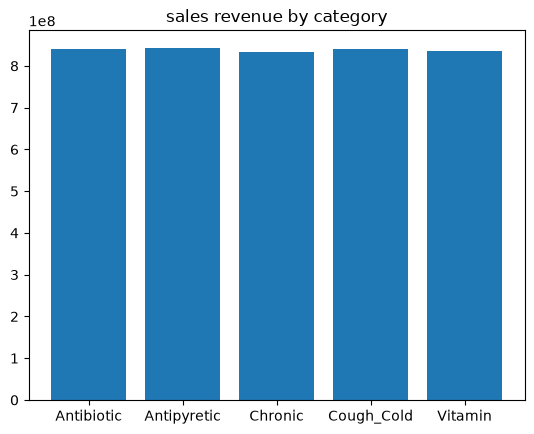

In [8]:
# plotting sales revenue by product category
category_sales = df.groupby('category')['revenue'].sum()
plt.bar(category_sales.index, category_sales.values)
plt.title('sales revenue by category')
plt.show()

<ipython-input-1-abe142d8f5a5>:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


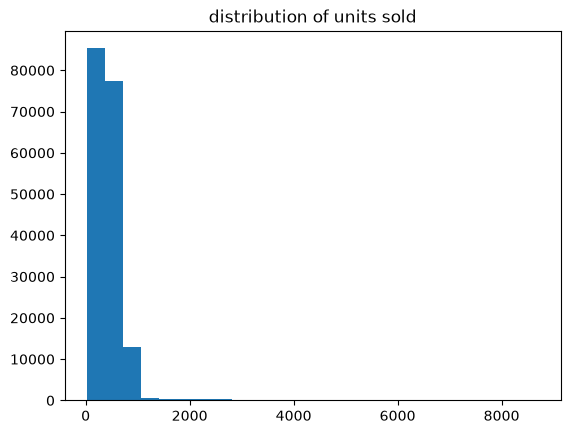

In [9]:
# plotting distribution of units sold
plt.hist(df['units_sold'], bins=25)
plt.title('distribution of units sold')
plt.show()

In [10]:
# defining data validation rules for user uploads
expected_columns = ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']

def validate_uploaded_data(data):
    missing = [col for col in expected_columns if col not in data.columns]
    if missing:
        return False, f"missing required columns: {missing}"
    if data.empty:
        return False, "file contains no data"
    if (data['units_sold'] < 0).any():
        return False, "negative values found in units_sold"
    if (data['unit_price'] < 0).any():
        return False, "negative values found in unit_price"
    return True, "dataset validation successful"

status, message = validate_uploaded_data(df)
print(status, message)

True dataset validation successful


In [11]:
# preparing features and target for prediction model
sample_df = df.sample(n=20000, random_state=42)
features = ['year', 'month', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'unit_price']
X = sample_df[features]
y = sample_df['units_sold']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train shape:', X_train.shape, 'test shape:', X_test.shape)

train shape: (16000, 6) test shape: (4000, 6)


In [12]:
# training random forest regression model
model = RandomForestRegressor(n_estimators=40, max_depth=10, random_state=42)
model.fit(X_train, y_train)

Out[1]: RandomForestRegressor(max_depth=10, n_estimators=40, random_state=42)


RandomForestRegressor(max_depth=10, n_estimators=40, random_state=42)

In [13]:
# evaluating model prediction metrics
y_pred = model.predict(X_test)
print('mean absolute error:', round(mean_absolute_error(y_test, y_pred), 2))
print('r2 score:', round(r2_score(y_test, y_pred), 4))

mean absolute error: 64.46
r2 score: 0.9408


In [14]:
# saving trained model for application deployment
joblib.dump(model, 'demand_model.pkl')
print('model successfully saved to demand_model.pkl')

model successfully saved to demand_model.pkl


In [15]:
# generating customized predictions on validated batch data
def predict_batch(input_df, model_path='demand_model.pkl'):
    predictor = joblib.load(model_path)
    feat_cols = ['year', 'month', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'unit_price']
    output_df = input_df.copy()
    output_df['predicted_units_sold'] = predictor.predict(output_df[feat_cols])
    return output_df

sample_batch = df.head(10)
results = predict_batch(sample_batch)
results[['medicine', 'category', 'stock_level', 'units_sold', 'predicted_units_sold']]

Out[1]: 
       medicine    category  stock_level  units_sold  predicted_units_sold
0    Amlodipine     Chronic         4774         328            233.604812
1    Amlodipine     Chronic         4584         371            390.132750
2     Vitamin C     Vitamin         3934         948            940.913479
3    Amlodipine     Chronic         4544         275            345.485104
4    Amlodipine     Chronic         4284         563            584.388415
5     Metformin     Chronic         4372         642            613.579810
6  Azithromycin  Antibiotic         4701         243            244.390534
7     Metformin     Chronic         4613         273            411.972757
8   Cough Syrup  Cough_Cold         4757         223            235.165073
9    Amlodipine     Chronic         4524         369            353.534969


,medicine,category,stock_level,units_sold,predicted_units_sold
0,Amlodipine,Chronic,4774,328,233.604812
1,Amlodipine,Chronic,4584,371,390.132750
2,Vitamin C,Vitamin,3934,948,940.913479
3,Amlodipine,Chronic,4544,275,345.485104
4,Amlodipine,Chronic,4284,563,584.388415
5,Metformin,Chronic,4372,642,613.579810
6,Azithromycin,Antibiotic,4701,243,244.390534
7,Metformin,Chronic,4613,273,411.972757
8,Cough Syrup,Cough_Cold,4757,223,235.165073
9,Amlodipine,Chronic,4524,369,353.534969


In [16]:
# creating complete streamlit application script
app_code = """
import streamlit as st
import pandas as pd
import joblib

st.title("Pharmacy Sales Analytics and Prediction")

uploaded_file = st.file_uploader("Upload CSV Dataset", type=['csv'])

if uploaded_file is not None:
    data = pd.read_csv(uploaded_file)
    st.subheader("Uploaded Data Preview")
    st.dataframe(data.head(10))
    
    required = ['year', 'month', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'unit_price']
    missing = [c for c in required if c not in data.columns]
    
    if missing:
        st.error(f"Missing columns: {missing}")
    else:
        st.success("Dataset validated successfully")
        
        if st.button("Generate Demand Predictions"):
            model = joblib.load('demand_model.pkl')
            data['predicted_units_sold'] = model.predict(data[required])
            st.subheader("Predictions Output")
            st.dataframe(data[['medicine', 'category', 'stock_level', 'predicted_units_sold']].head(20))
"""
with open('app.py', 'w') as f:
    f.write(app_code.strip())
print('app.py generated successfully')

app.py generated successfully


In [17]:
# testing validation on invalid uploaded sample
invalid_df = pd.DataFrame({'sample_col': [1, 2, 3]})
is_valid, err_msg = validate_uploaded_data(invalid_df)
print('validation status:', is_valid)
print('error report:', err_msg)

validation status: False
error report: missing required columns: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
